# Setup
Set-up Keras (in order to use nnodely) in configuration "torch" to use PyTorch.
Import libraries to navigate repository, generate figures and open `.np` files (LUT table).

In [4]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import nnodely
import time
import json

print(f"nnodely version: {nnodely.__version__}")
print(f"Backend used: {os.environ.get('KERAS_BACKEND')}")
print("Setup completed!")

nnodely version: 2.0.0
Backend used: torch
Setup completed!


# Convert `nc` to `csv` and Rename Variable
To better visualize the LUT, convert the `.nc` file into a `.csv` (step not strictly necessary as we will use `nnodely` directly with the `.nc` file).
Rename `__xarray_dataarray_variable__` (default name in a file `.nc`) into `activation_value`.

In [2]:
PATH_FILE_NC = "models/comb_lut_W=0.2.nc"
PATH_FILE_CSV = "models/comb_lut_W=0.2.csv"

OLD_VAR_NAME = "max_torque"
NEW_VAR_NAME = "torque_max"


ds = xr.open_dataset(PATH_FILE_NC)
if OLD_VAR_NAME in ds:
    ds = ds.rename({OLD_VAR_NAME : NEW_VAR_NAME})
ds.load()
ds.close() #close file, otherwise impossible to save it
ds.to_netcdf(PATH_FILE_NC)

df = ds.to_dataframe()
df = df.reset_index()
df = df.dropna()
df.to_csv(PATH_FILE_CSV, index=False)

print(f"File CSV saved in: {PATH_FILE_CSV}")
print(f"File NC updated in: {PATH_FILE_NC}")
print(f"Number of valid rows of CSV: {len(df)}")

File CSV saved in: models/comb_lut_W=0.2.csv
File NC updated in: models/comb_lut_W=0.2.nc
Number of valid rows of CSV: 6882


# LUT Upload
Open the `.nc` file and remove the NaN.
Build the LUT Matrix starting from the `.nc` file.
The numer of rows of the LUT matrix should be the valid rows of CSV divided by 6.
In the `.nc` file, values are stored as `float64`, but PyTorch will convert it into `float32`.

In [5]:
LUT_PATH = "models/comb_lut_W=0.2.nc"

#ds = DataSet
ds = xr.open_dataset(LUT_PATH)

#df = DataFrame
df = ds.to_dataframe().reset_index().dropna()
pivot_df = df.pivot_table(
    index = ['angle', 'torque_norm'], 
    columns = 'activation_idx',
    values = 'activation_value',
).reset_index()

lut_data = {
    "angle": pivot_df["angle"].values.astype(np.float32),
    "torque_norm": pivot_df["torque_norm"].values.astype(np.float32),
    "activations_target": pivot_df.iloc[:, 2:8].values.astype(np.float32)
}

angle_MIN = float(lut_data["angle"].min())
angle_MAX = float(lut_data["angle"].max())

print("Dataset LUT uploaded!")
print(f"LUT matrix dimension: {lut_data['activations_target'].shape}")

Dataset LUT uploaded!
LUT matrix dimension: (1147, 6)


# LUT Visualization
Heat-map to visualize the intensity of the muscle.
Insert negative values for `ANGLE_REQ` or `TAU_REQ` if you wanto to analize the general case.

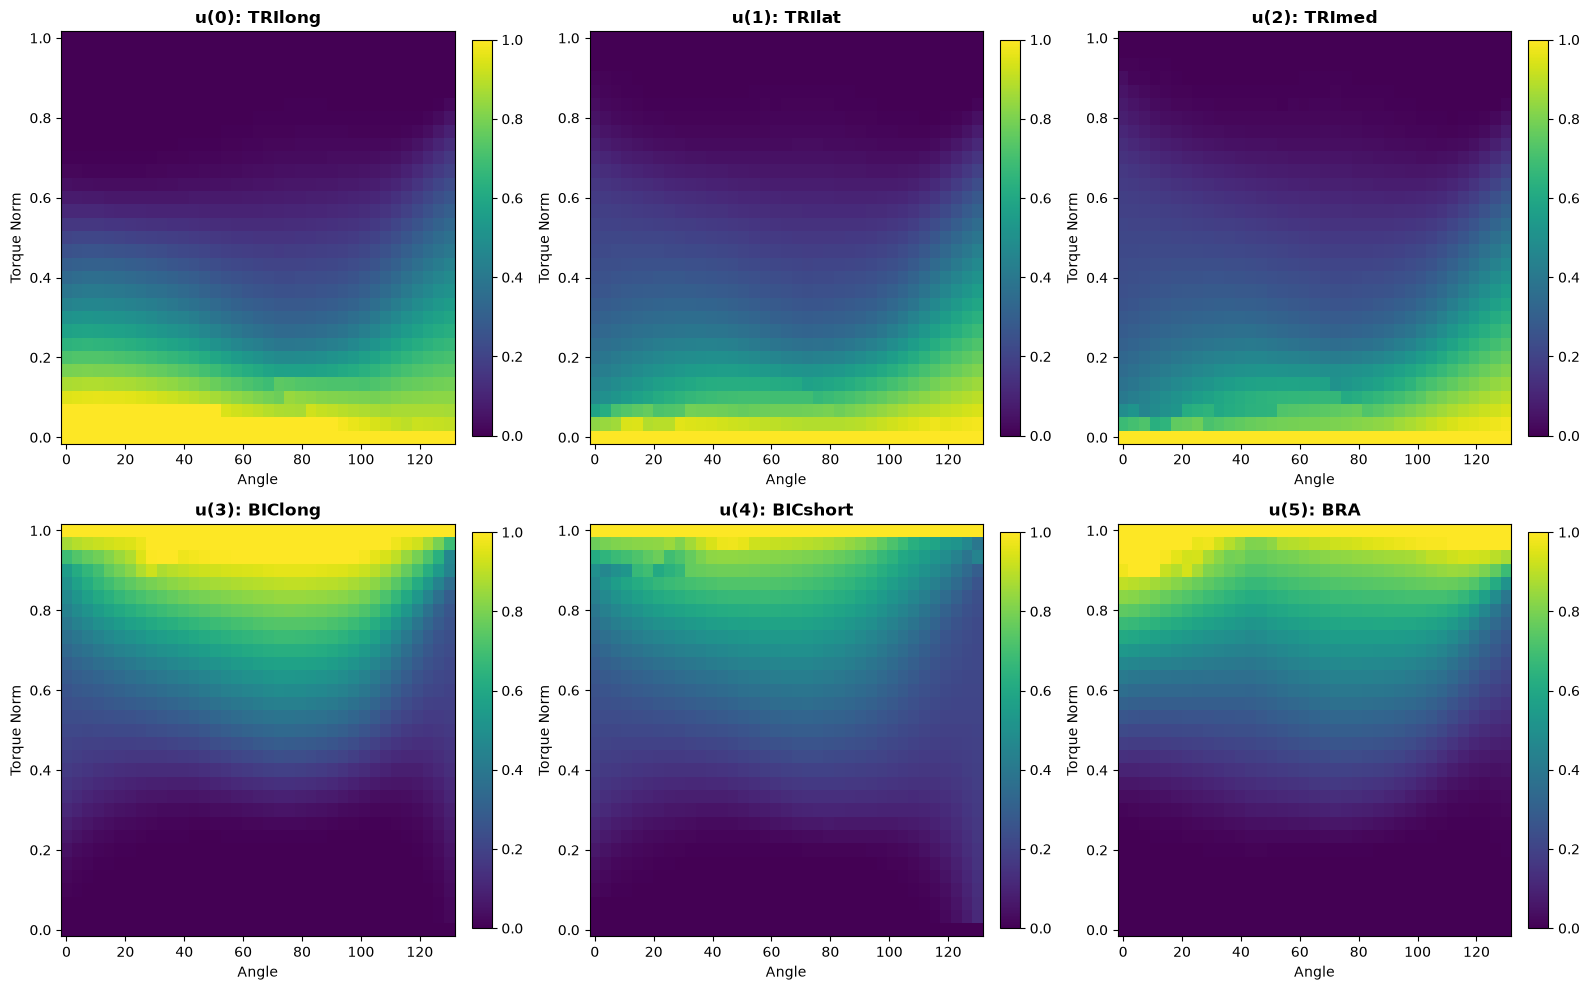

In [6]:
ANGLE_REQ = -45.0
TAU_REQ = 0.5

muscle_names = ["TRIlong", "TRIlat", "TRImed", "BIClong", "BICshort", "BRA"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

visualize_square = False
if ANGLE_REQ>0.0 and ANGLE_REQ<130.0 and TAU_REQ>0.0 and TAU_REQ<1.0:
    visualize_square = True
    activations_found = {}

for i, muscle in enumerate(muscle_names):
    heatmap_data = pivot_df.pivot(index='torque_norm', columns='angle', values=i)
    
    X = heatmap_data.columns.values
    Y = heatmap_data.index.values
    Z = heatmap_data.values
    
    im = axes[i].pcolormesh(X, Y, Z, cmap='viridis', shading='auto')

    if (visualize_square):
        idx_angle = (np.abs(X - ANGLE_REQ)).argmin()
        idx_tau = (np.abs(Y - TAU_REQ)).argmin()
        
        closest_angle = X[idx_angle]
        closest_tau = Y[idx_tau]
        activations_found[muscle] = Z[idx_tau, idx_angle]

        axes[i].plot(closest_angle, closest_tau, marker='s', color='red', alpha=0.4, markersize=10)
    
    axes[i].set_title(f'u({i}): {muscle}', fontweight='bold')
    axes[i].set_xlabel('Angle')
    axes[i].set_ylabel('Torque Norm')
    
    fig.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

if (visualize_square):
    print(f"Values for (Angle ~{closest_angle:.2f}, Torque~{closest_tau:.2f})")
    for muscle, act_val in activations_found.items():
        print(f"{muscle}: {act_val:.4f}")

# NN Setup
We need to define the number of layers and of neurons of the Neural Network.
The input is $x_{in}=[\theta, \tau_{norm}]^T$ and output is $u_{out}=[u(0),\dots, u(5)]^T$.

Note that it is necessary to pre-process the data. Due to the fact that $\tau_{norm} \in [0,1]$ and $\theta \in [0°,130°]$, variation of $\tau_{norm}$ will be ininfluent to the NN weight variation. Therefore, we neet to normalize the inputs of the dataset.

In [15]:
NN_NAME = "comb_lut_W=0.2_nn"
NUM_HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32

from nnodely import (
    Modely, Input, Output, Linear, Sigmoid, ReLU, Clamp, Concatenate, DataLoader, set_seed
    )
set_seed(42) #random seed to ensure reproducible results across runs

angle = Input("angle")
angle_norm = (angle.last() - angle_MIN) / (angle_MAX - angle_MIN)
torque_norm = Input("torque_norm")

x_in = Concatenate()([angle_norm, torque_norm.last()])
h = x_in
for _ in range(NUM_HIDDEN_LAYERS):
  h = ReLU()(Linear(out_features=HIDDEN_UNITS)(h))

u_raw = Linear(out_features=6)(h)
u_bounded = Sigmoid()(u_raw)
u_pred = Output("activations_pred", u_bounded)

u_target = Input("activations_target", dim=6)

model = Modely(
    name=NN_NAME,
    inputs=[angle, torque_norm],
    outputs=[u_pred]
)

model.minimize(
    name=NN_NAME,
    source=u_pred,
    target=u_target.last(),
    loss="mse"
)
model.build()

print(f"Architecture of the NN: {NUM_HIDDEN_LAYERS} layers of {HIDDEN_UNITS} neurons each.")
model.summary()

Architecture of the NN: 2 layers of 32 neurons each.


Model: "comb_lut_W=0.2_nn_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow27      │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract28          │ (None, 1, 1)      │          0 │ SampleWindow27[0… │
│ (BinaryOpImpl)      │                   │            │ Constant3[2][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide29            │ (None, 1, 1)      │          0 │ Subtract28[0][0], │
│ (BinaryOpImpl)      │                   │            │ Constant5[2][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow31      │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate30       │ (None, 2, 1)      │          0 │ Divide29[0][0],   │
│ (ConcatenateImpl)   │                   │            │ SampleWindow31[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear33            │ (None, 32, 1)     │         96 │ Concatenate30[0]… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU32 (ReLU)       │ (None, 32, 1)     │          0 │ Linear33[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear35            │ (None, 32, 1)     │      1,056 │ ReLU32[0][0]      │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU34 (ReLU)       │ (None, 32, 1)     │          0 │ Linear35[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear36            │ (None, 6, 1)      │        198 │ ReLU34[0][0]      │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow38      │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sigmoid37           │ (None, 6, 1)      │          0 │ Linear36[0][0]    │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,352 (5.28 KB)

 Trainable params: 1,350 (5.27 KB)

 Non-trainable params: 2 (8.00 B)

# NN Training

shuffle=True,       # Rimescola i batch a ogni epoca per evitare bias di ordinamento

In [16]:

EPOCHS = 100
BATCH_SIZE = 16
LEARNING_RATE = 1e-3

full_dataset = DataLoader(model, source=lut_data)

print(f"Number of rows in the dataset: {len(lut_data['angle'])}")
print(f"Training for {EPOCHS} epochs...\n")

history = model.train(
    full_dataset,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LEARNING_RATE,
    shuffle=True,
    printer="legacy"
)

print("\nTraining finished!")



Number of rows in the dataset: 1147
Training for 100 epochs...

================= nnodely Training =================
|  Epoch   | comb_lut_W=0.2_nn |       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|  5/100   |  0.00639|    -    |  0.00638|    -    |
|  10/100  |  0.00463|    -    | 0.004611|    -    |
|  15/100  | 0.004054|    -    | 0.004058|    -    |
|  20/100  | 0.003706|    -    | 0.003701|    -    |
|  25/100  | 0.003357|    -    | 0.003348|    -    |
|  30/100  |  0.00313|    -    | 0.003128|    -    |
|  35/100  | 0.002914|    -    | 0.002907|    -    |
|  40/100  | 0.002731|    -    | 0.002721|    -    |
|  45/100  | 0.002557|    -    | 0.002561|    -    |
|  50/100  | 0.002477|    -    | 0.002472|    -    |
|  55/100  | 0.002379|    -    | 0.002383|    -    |
|  60/100  | 0.002346|    -    | 0.002349|    -    |
|  65/100  | 0.002304|    -    | 0.

# NN Plot Results

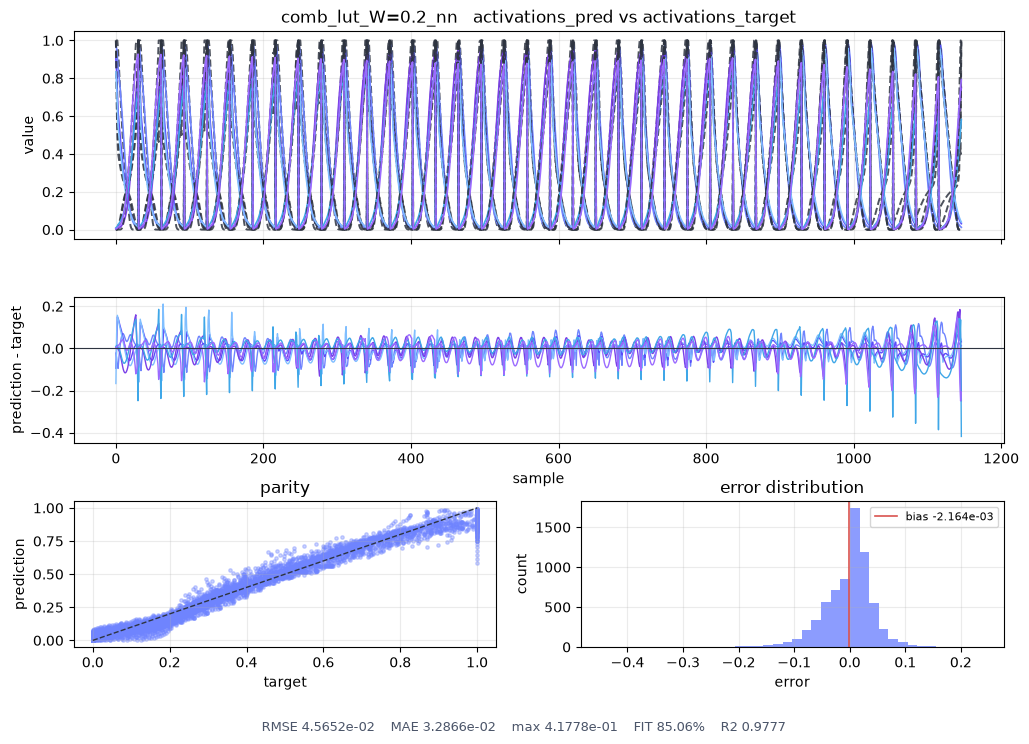

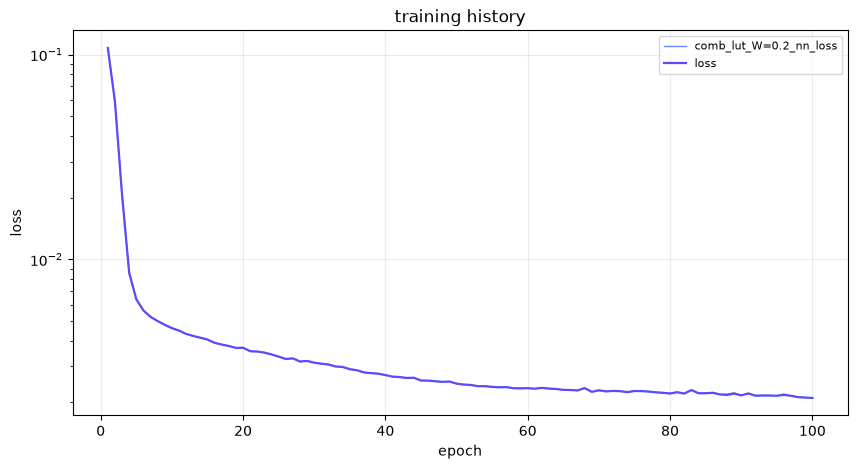

============================== nnodely Validation ==============================
Model:                        comb_lut_W=0.2_nn
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
comb_lut_W=0.2_nn   (activations_pred vs activations_target)
  Loss (mean_squared_error)   2.084087e-03
  RMSE                        4.565180e-02
  MAE                         3.286635e-02
  Max error                   4.177779e-01
  Bias (mean error)           -2.164396e-03
  Error std                   4.560046e-02
  NRMSE (% of range)          4.565 %
  FIT (% variance)            85.062 %
  R2                          0.977684
  Correlation                 0.989018
--------------------------------------------------------------------------------
  Figure:                     plots\comb_lut_W_0_2_nn_comb_lut_W_0_2_nn.png
  Figure:                     plots\comb_lut_W_0_2_nn_history.png


In [17]:
PATH_PLOT_SAVED = "plots"

os.makedirs("models", exist_ok=True)
os.makedirs(PATH_PLOT_SAVED, exist_ok=True)

# plots
result = model.validate(
    full_dataset,
    history=history,        # data to generate the plots
    out_dir=PATH_PLOT_SAVED,
    show=True,              # show here in notebook
    verbose=True            # print table
)

# NN Export Model

In [18]:
PATH_EXPORT_MODEL = "models"

os.makedirs(PATH_EXPORT_MODEL, exist_ok=True)

model.export_keras(PATH_EXPORT_MODEL, filename=NN_NAME)
print(f"\nModel Keras saved in: {PATH_EXPORT_MODEL}/{NN_NAME}.keras")

model.save(f"{PATH_EXPORT_MODEL}/{NN_NAME}")
print(f"Model nnodely saved in: {PATH_EXPORT_MODEL}/{NN_NAME}/")

metadata_model = {
    "model_name": NN_NAME,
    "hyperparameters": {
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "hidden_layers": NUM_HIDDEN_LAYERS,
        "hidden_units": HIDDEN_UNITS,
    },
    "validation_metrics": result[NN_NAME].metrics,
    "history": history,
}

# 3. Salvataggio del file JSON
metadata_path = f"{PATH_EXPORT_MODEL}/{NN_NAME}_metadata.json"
with open(metadata_path, "w") as f:
    json.dump(metadata_model, f, indent=4) 

print(f"Metadata, metrics and history saved in: {metadata_path}")


Model Keras saved in: models/comb_lut_W=0.2_nn.keras
Model nnodely saved in: models/comb_lut_W=0.2_nn/
Metadata, metrics and history saved in: models/comb_lut_W=0.2_nn_metadata.json
